# PreTest 02: Regression แบบครบวงจร — การทำนายค่าเบี้ยประกันสุขภาพ
### จากข้อมูลดิบ → ทำความสะอาด → Visualization → เตรียมข้อมูล → เทรน 3 โมเดล → วัดผล → เลือกโมเดล

> **ที่มา:** ดัดแปลงและขยายจาก Kaggle Notebook
> [Linear Regression Tutorial](https://www.kaggle.com/code/sudhirnl7/linear-regression-tutorial) โดย sudhirnl7
> สิ่งที่เพิ่ม/แก้: คำอธิบายภาษาไทยทุกขั้นตอน, ตรวจ/ลบข้อมูลซ้ำ, Metrics ครบ (MAE, RMSE, R²) ทั้งสเกล log และสเกลเงินจริง,
> เพิ่มโมเดล **Decision Tree** และ **Random Forest**, Cross-Validation, ตารางเปรียบเทียบ 3 โมเดล, แก้โค้ดให้ใช้กับ seaborn/sklearn ปัจจุบัน
>
> **ชุดข้อมูล (Dataset):** [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance) — ค่าประกันสุขภาพรายปีของคนในสหรัฐฯ 1,338 คน

---

## ภาพรวมขั้นตอน

| ขั้น | งาน | คำถามที่ต้องตอบ |
|---|---|---|
| 1 | กำหนดโจทย์ | ทำนายอะไร? วัดผลด้วยอะไร? |
| 2–3 | โหลดและสำรวจข้อมูล | แต่ละคอลัมน์คืออะไร? |
| 4 | ทำความสะอาด | ค่าหาย? ข้อมูลซ้ำ? Outlier? |
| 5 | EDA & Visualization | Target กระจายตัวอย่างไร? อะไรทำให้ค่าประกันแพง? |
| 6 | เตรียมข้อมูล | Encode → แปลง Target → Split |
| 7–9 | เทรนโมเดล 3 ตัว | Linear Regression, Decision Tree, Random Forest |
| 10 | เปรียบเทียบและเลือกโมเดล | ตัวไหนดีที่สุด เพราะอะไร? |

---
# ขั้นที่ 1: กำหนดโจทย์

- **เป้าหมาย:** ทำนาย **ค่าประกันสุขภาพต่อปี** (`charges`, หน่วย USD) จากข้อมูลส่วนตัวของผู้ทำประกัน
- **ประเภทปัญหา:** Target เป็นตัวเลขต่อเนื่อง → **Regression**
- **วัดผลด้วย:**

| Metric | สูตร (โดยย่อ) | ความหมาย | ดีเมื่อ |
|---|---|---|---|
| **MAE** | เฉลี่ยของ \|จริง − ทำนาย\| | ทำนายพลาดเฉลี่ยกี่ดอลลาร์ | ต่ำ |
| **RMSE** | √(เฉลี่ยของ (จริง − ทำนาย)²) | เหมือน MAE แต่ลงโทษการพลาดมากๆ หนักกว่า | ต่ำ |
| **R²** | 1 − (SSE / SST) | อธิบายความแปรปรวนของ Target ได้กี่ % | ใกล้ 1 |

---
# ขั้นที่ 2: นำเข้าไลบรารีและโหลดข้อมูล

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

In [2]:
DATA_FILE = "Data/insurance.csv"

if not os.path.exists(DATA_FILE):
    # ไม่มีไฟล์ในเครื่อง → ดาวน์โหลดจาก Kaggle (ถ้า error ให้รัน !pip install kagglehub ก่อน)
    import kagglehub
    DATA_FILE = os.path.join(kagglehub.dataset_download("mirichoi0218/insurance"), "insurance.csv")

df = pd.read_csv(DATA_FILE)
print("ขนาดข้อมูล (แถว, คอลัมน์):", df.shape)
df.head()

ขนาดข้อมูล (แถว, คอลัมน์): (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


---
# ขั้นที่ 3: สำรวจข้อมูลเบื้องต้น

| คอลัมน์ | ความหมาย | ชนิด |
|---|---|---|
| `age` | อายุผู้ทำประกัน | Numerical |
| `sex` | เพศ (male/female) | Categorical |
| `bmi` | ดัชนีมวลกาย (kg/m²) — ค่าตั้งแต่ 30 ขึ้นไปจัดเป็นภาวะอ้วน | Numerical |
| `children` | จำนวนบุตรที่อยู่ในประกัน (0–5) | Numerical (ค่าไม่ต่อเนื่อง) |
| `smoker` | สูบบุหรี่หรือไม่ (yes/no) | Categorical |
| `region` | ภูมิภาคที่อยู่ในสหรัฐฯ (4 ภาค) | Categorical |
| **`charges`** | **ค่าประกันต่อปี (USD) ← Target** | Numerical |

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
df.describe().round(2)

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


In [5]:
for col in ['sex', 'smoker', 'region']:
    print(df[col].value_counts().to_dict())

{'male': 676, 'female': 662}
{'no': 1064, 'yes': 274}
{'southeast': 364, 'southwest': 325, 'northwest': 325, 'northeast': 324}


> **ข้อสังเกต:** `charges` มีตั้งแต่ ~1,100 ถึง ~63,800 ดอลลาร์ และค่าเฉลี่ย (13,270) **สูงกว่า** median (9,382) มาก → การกระจาย **เบ้ขวา**
> ผู้สูบบุหรี่มี 274 คน (~20%)

---
# ขั้นที่ 4: ทำความสะอาดข้อมูล

### 4.1 ค่าที่หาย (Missing Values)

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


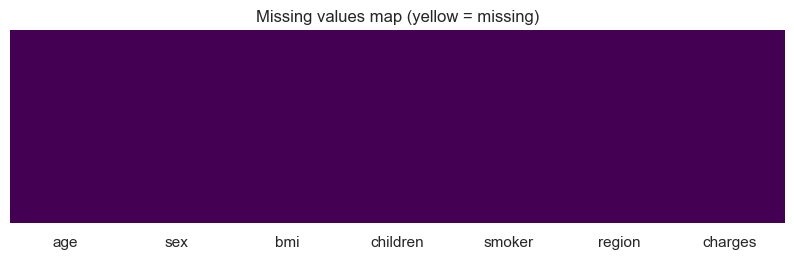

In [6]:
print(df.isnull().sum())

plt.figure(figsize=(10, 2.5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing values map (yellow = missing)')
plt.show()

> **ผลลัพธ์:** ไม่มีค่าหาย (ถ้ามี ให้ใช้เทคนิคจากบท 02-2 เช่นเติมด้วย median/mode)

### 4.2 ข้อมูลซ้ำ (Duplicates)

In [7]:
print("จำนวนแถวซ้ำ:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])

df = df.drop_duplicates().reset_index(drop=True)
print("ขนาดหลังลบแถวซ้ำ:", df.shape)

จำนวนแถวซ้ำ: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


ขนาดหลังลบแถวซ้ำ: (1337, 7)


> **หมายเหตุ:** พบ 1 แถวที่ซ้ำกันทุกคอลัมน์ ซึ่งเป็นไปได้ยากในข้อมูลจริง (อายุ เพศ BMI ค่าประกันเท่ากันทุกค่า) จึงลบออก

### 4.3 ตรวจ Outlier

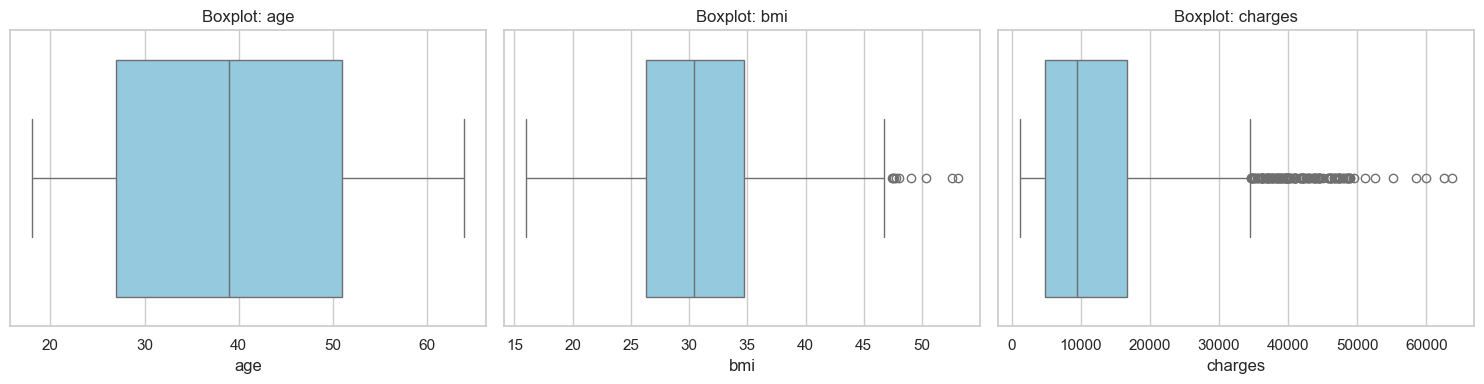

bmi      ขอบบน (1.5×IQR) = 47.3 → outlier 9 แถว
charges  ขอบบน (1.5×IQR) = 34,524.8 → outlier 139 แถว


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['age', 'bmi', 'charges']):
    sns.boxplot(x=df[col], ax=ax, color='skyblue')
    ax.set_title(f'Boxplot: {col}')
plt.tight_layout(); plt.show()

for col in ['bmi', 'charges']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    print(f"{col:8s} ขอบบน (1.5×IQR) = {upper:,.1f} → outlier {(df[col] > upper).sum()} แถว")

> **ตัดสินใจ: ไม่ลบ Outlier** เพราะ
> - `charges` สูง **เป็นค่าจริง** ของกลุ่มผู้สูบบุหรี่ (จะเห็นในขั้นที่ 5) ไม่ใช่ข้อมูลผิด — ถ้าลบ โมเดลจะทำนายคนกลุ่มนี้ไม่ได้
> - `bmi` สูงสุด ~53 ยังเป็นค่าที่เป็นไปได้ทางการแพทย์
>
> **หลักคิด:** ลบ Outlier เฉพาะเมื่อมั่นใจว่าเป็น **ข้อมูลผิดพลาด** เท่านั้น

---
# ขั้นที่ 5: EDA & Visualization

### 5.1 การกระจายของ Target (`charges`)

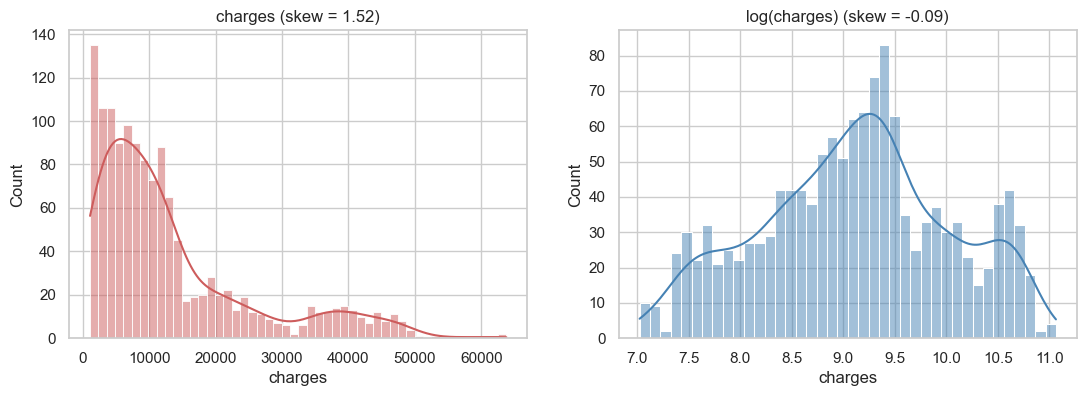

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['charges'], bins=50, kde=True, color='indianred', ax=axes[0])
axes[0].set_title(f"charges (skew = {df['charges'].skew():.2f})")
sns.histplot(np.log(df['charges']), bins=40, kde=True, color='steelblue', ax=axes[1])
axes[1].set_title(f"log(charges) (skew = {np.log(df['charges']).skew():.2f})")
plt.show()

> **ข้อสังเกต:** ซ้าย: เบ้ขวามาก (skew ≈ 1.5) / ขวา: หลังใส่ log ใกล้ระฆังคว่ำมากขึ้น (skew ≈ −0.1)
> → เราจะ **ทำนาย `log(charges)`** เพราะ Linear Regression ทำงานได้ดีเมื่อ Target ไม่เบ้มาก แล้วค่อยแปลงกลับเป็นดอลลาร์ด้วย `exp()`

### 5.2 ตัวแปร Categorical กับค่าประกัน

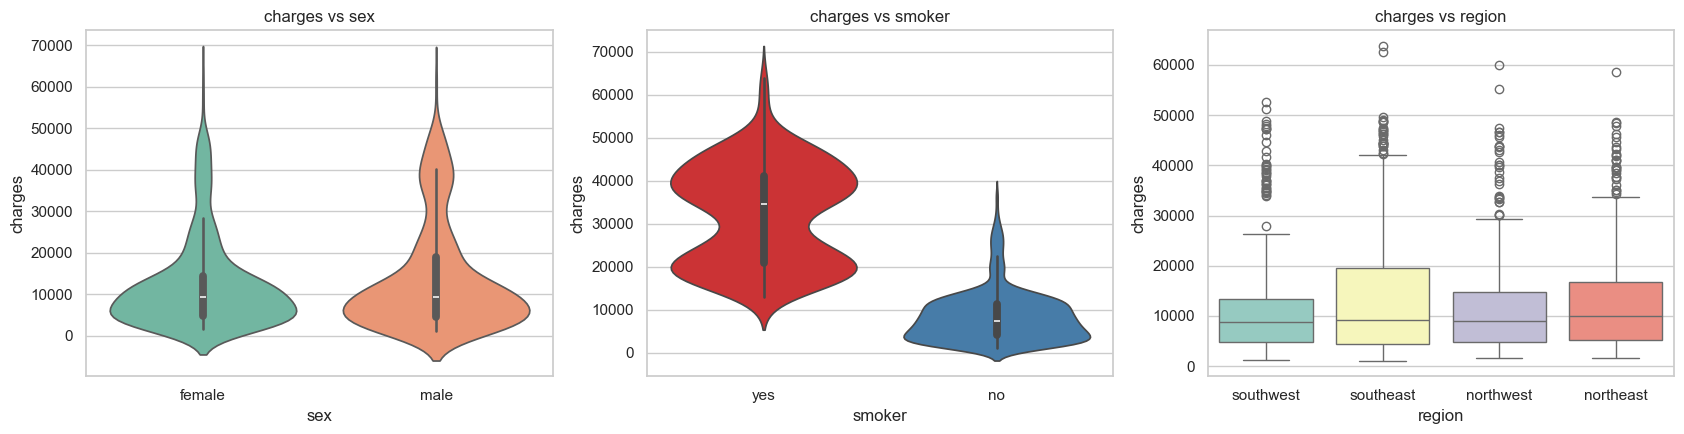

,mean,median,count
smoker,,,
no,8441.0,7346.0,1063
yes,32050.0,34456.0,274


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.violinplot(x='sex', y='charges', data=df, ax=axes[0], palette='Set2', hue='sex', legend=False)
axes[0].set_title('charges vs sex')
sns.violinplot(x='smoker', y='charges', data=df, ax=axes[1], palette='Set1', hue='smoker', legend=False)
axes[1].set_title('charges vs smoker')
sns.boxplot(x='region', y='charges', data=df, ax=axes[2], palette='Set3', hue='region', legend=False)
axes[2].set_title('charges vs region')
plt.tight_layout(); plt.show()

df.groupby('smoker')['charges'].agg(['mean', 'median', 'count']).round(0)

> **ผู้สูบบุหรี่จ่ายแพงกว่าประมาณ 4 เท่า** (เฉลี่ย ~32,000 vs ~8,400) → `smoker` น่าจะเป็นตัวแปรสำคัญที่สุด
> เพศและภูมิภาคต่างกันไม่มาก

### 5.3 จำนวนบุตรกับค่าประกัน

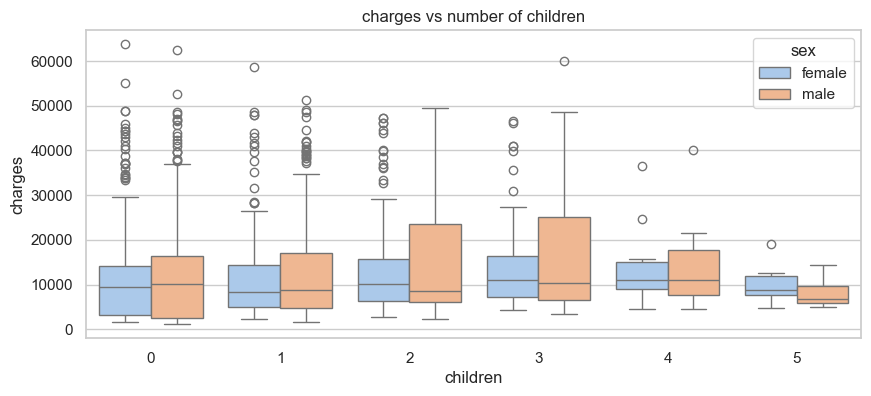

,mean,min,max,count
children,,,,
0,12385.0,1122.0,63770.0,573
1,12731.0,1711.0,58571.0,324
2,15074.0,2304.0,49578.0,240
3,15355.0,3443.0,60021.0,157
4,13851.0,4505.0,40182.0,25
5,8786.0,4688.0,19023.0,18


In [11]:
plt.figure(figsize=(10, 4))
sns.boxplot(x='children', y='charges', hue='sex', data=df, palette='pastel')
plt.title('charges vs number of children')
plt.show()

df.groupby('children')['charges'].agg(['mean', 'min', 'max', 'count']).round(0)

### 5.4 อายุ / BMI กับค่าประกัน แยกตามการสูบบุหรี่ (กราฟสำคัญที่สุด)

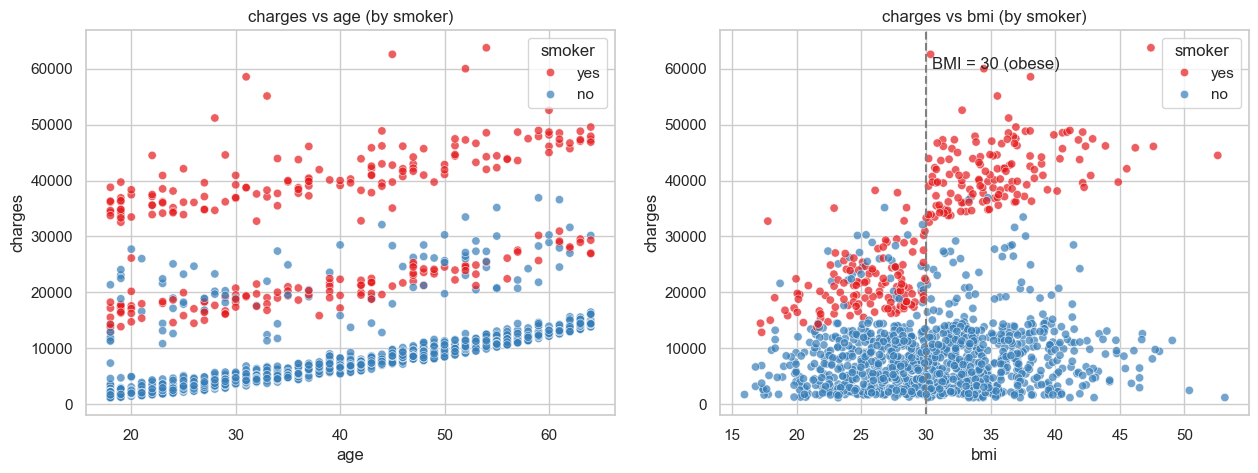

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, palette='Set1', alpha=0.7, ax=axes[0])
axes[0].set_title('charges vs age (by smoker)')
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, palette='Set1', alpha=0.7, ax=axes[1])
axes[1].axvline(30, ls='--', c='gray'); axes[1].text(30.5, 60000, 'BMI = 30 (obese)')
axes[1].set_title('charges vs bmi (by smoker)')
plt.show()

> **Insight สำคัญ:**
> - **อายุ:** ค่าประกันเพิ่มตามอายุเป็นเส้นตรง แยกเป็น 3 "ชั้น" ตามสถานะสูบบุหรี่
> - **BMI:** สำหรับคน **ไม่สูบ** BMI แทบไม่มีผล แต่ **ผู้สูบที่ BMI ≥ 30 ค่าประกันกระโดดขึ้นไปอีกระดับ**
> - นี่คือ **Interaction** (ผลของ BMI ขึ้นกับการสูบบุหรี่) ซึ่ง Linear Regression ธรรมดา **จับไม่ได้** แต่ Tree จับได้ → จะเห็นผลในขั้นที่ 10

### 5.5 Correlation (ตัวแปรตัวเลข)

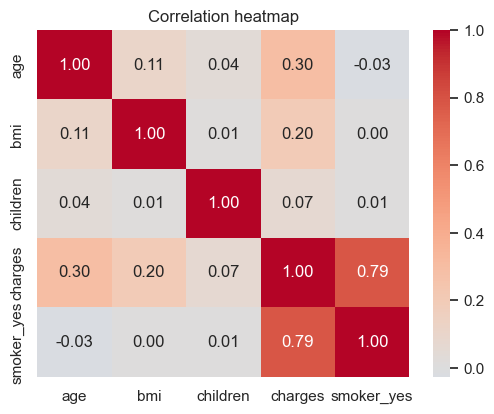

In [13]:
corr_df = df.assign(smoker_yes=(df['smoker'] == 'yes').astype(int))
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr_df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap')
plt.show()

> **ข้อสังเกต:** `smoker_yes` สัมพันธ์กับ `charges` สูงมาก (~0.79) รองลงมาคือ `age` (~0.30) และ `bmi` (~0.20)
> ตัวแปรต้นด้วยกันเองไม่สัมพันธ์กันมาก → ไม่มีปัญหา Multicollinearity

---
# ขั้นที่ 6: เตรียมข้อมูลสำหรับโมเดล

### 6.1 One-Hot Encoding และ Dummy Variable Trap
- แปลง `sex`, `smoker`, `region`, `children` เป็นคอลัมน์ 0/1
- `drop_first=True` → ตัดหมวดแรกทิ้ง 1 คอลัมน์ เพราะรู้ค่าได้จากคอลัมน์ที่เหลือ
  (เช่น ถ้า `sex_male = 0` ก็รู้ว่าเป็น female) ถ้าไม่ตัด จะเกิด **Dummy Variable Trap** ทำให้ Linear Regression คำนวณไม่เสถียร
- `children` เป็นตัวเลขก็จริง แต่ต้นฉบับมองเป็นหมวดหมู่ (ผลของจำนวนบุตรอาจไม่เป็นเส้นตรง)

In [14]:
categorical_columns = ['sex', 'children', 'smoker', 'region']
df_encode = pd.get_dummies(df, columns=categorical_columns, prefix=categorical_columns,
                           drop_first=True, dtype=int)

print("คอลัมน์เดิม :", list(df.columns))
print("หลัง Encode:", list(df_encode.columns))
df_encode.head()

คอลัมน์เดิม : ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
หลัง Encode: ['age', 'bmi', 'charges', 'sex_male', 'children_1', 'children_2', 'children_3', 'children_4', 'children_5', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


,age,bmi,charges,sex_male,children_1,children_2,children_3,children_4,children_5,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,16884.92400,0,0,0,0,0,0,1,0,0,1
1,18,33.770,1725.55230,1,1,0,0,0,0,0,0,1,0
2,28,33.000,4449.46200,1,0,0,1,0,0,0,0,1,0
3,33,22.705,21984.47061,1,0,0,0,0,0,0,1,0,0
4,32,28.880,3866.85520,1,0,0,0,0,0,0,1,0,0


### 6.2 แปลง Target ด้วย log
(ต้นฉบับทดลอง Box-Cox ด้วย แต่ผลไม่ดีกว่า log จึงใช้ log ซึ่งง่ายกว่า)

In [15]:
df_encode['log_charges'] = np.log(df_encode['charges'])
df_encode = df_encode.drop(columns='charges')

### 6.3 แบ่ง Train / Test (70 / 30)

In [16]:
from sklearn.model_selection import train_test_split

X = df_encode.drop(columns='log_charges')
y = df_encode['log_charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=23)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (935, 12)  Test: (402, 12)


> **หมายเหตุ:** ข้อมูลชุดนี้ไม่ต้อง Scale เพราะ Linear Regression แบบไม่มี Regularization ไม่ได้รับผลจากสเกล และโมเดลกลุ่ม Tree ไม่ได้รับผลจากสเกล
> (ถ้าใช้ KNN, SVR, Ridge/Lasso ควร Scale)

### 6.4 ฟังก์ชันวัดผล (ใช้ซ้ำกับทุกโมเดล)
วัดทั้งในสเกล log (ที่โมเดลเรียน) และ **สเกลดอลลาร์จริง** (ที่คนเข้าใจ) ด้วยการแปลงกลับด้วย `np.exp`

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(model, name):
    pred_log = model.predict(X_test)
    actual_usd, pred_usd = np.exp(y_test), np.exp(pred_log)
    return {'Model': name,
            'R² train (log)': r2_score(y_train, model.predict(X_train)),
            'R² test (log)':  r2_score(y_test, pred_log),
            'MAE ($)':        mean_absolute_error(actual_usd, pred_usd),
            'RMSE ($)':       np.sqrt(mean_squared_error(actual_usd, pred_usd)),
            'R² test ($)':    r2_score(actual_usd, pred_usd)}

---
# ขั้นที่ 7: โมเดลที่ 1 — Linear Regression

### หลักการ
หาเส้น (ระนาบ) ที่ใกล้ทุกจุดที่สุด: `ŷ = θ₀ + θ₁x₁ + θ₂x₂ + … + θₙxₙ`

- **Cost function (MSE):** `J(θ) = (1/m) Σ (ŷᵢ − yᵢ)²` → หาค่า θ ที่ทำให้ J ต่ำสุด
- **Normal Equation:** หาคำตอบได้โดยตรงด้วยสูตร `θ = (XᵀX)⁻¹ Xᵀy`

### 7.1 ภาพตัวอย่าง: เส้นตรง 1 ตัวแปร (BMI → charges)

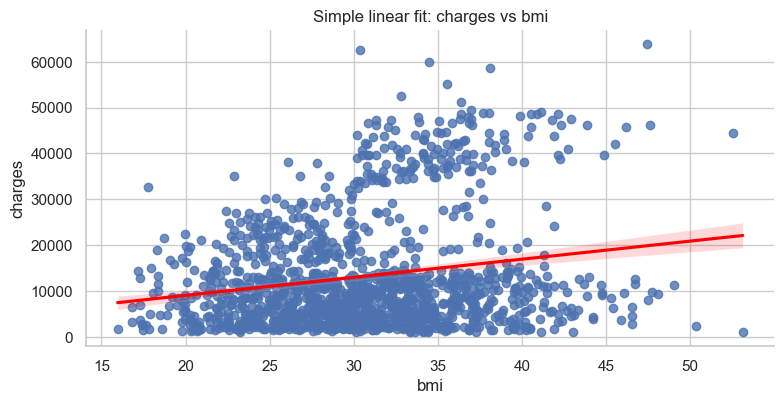

In [18]:
sns.lmplot(x='bmi', y='charges', data=df, aspect=2, height=4, line_kws={'color': 'red'})
plt.title('Simple linear fit: charges vs bmi')
plt.show()

### 7.2 คำนวณด้วยมือ (Normal Equation) เทียบกับ scikit-learn

In [19]:
# เพิ่มคอลัมน์ x0 = 1 สำหรับค่าคงที่ θ0
X_train_0 = np.c_[np.ones((X_train.shape[0], 1)), X_train]

# θ = (XᵀX)⁻¹ Xᵀy
theta = np.linalg.inv(X_train_0.T @ X_train_0) @ (X_train_0.T @ y_train)

from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

params = pd.DataFrame({'Feature': ['intercept'] + list(X.columns),
                       'θ (Normal Equation)': theta,
                       'θ (sklearn)': [lin_reg.intercept_] + list(lin_reg.coef_)})
params.round(4)

,Feature,θ (Normal Equation),θ (sklearn)
0,intercept,7.0889,7.0889
1,age,0.0338,0.0338
2,bmi,0.0117,0.0117
3,sex_male,-0.0746,-0.0746
4,children_1,0.1587,0.1587
5,children_2,0.2362,0.2362
6,children_3,0.2226,0.2226
7,children_4,0.5680,0.5680
8,children_5,0.4314,0.4314
9,smoker_yes,1.5546,1.5546


> **ผลลัพธ์:** สองวิธีได้ค่าเท่ากัน → `LinearRegression().fit()` ก็คือการแก้สมการนี้ให้เรานั่นเอง

### 7.3 ตีความ Coefficient
Target เป็น log → coefficient θ หมายถึง **ค่าประกันเปลี่ยนไปประมาณ (e^θ − 1) × 100%**

In [20]:
coef = pd.Series(lin_reg.coef_, index=X.columns)
pd.DataFrame({'coef': coef.round(3), 'ผลต่อค่าประกัน (%)': ((np.exp(coef) - 1) * 100).round(1)}).sort_values('coef', ascending=False)

,coef,ผลต่อค่าประกัน (%)
smoker_yes,1.555,373.3
children_4,0.568,76.5
children_5,0.431,53.9
children_2,0.236,26.6
children_3,0.223,24.9
children_1,0.159,17.2
age,0.034,3.4
bmi,0.012,1.2
region_northwest,-0.041,-4.0
sex_male,-0.075,-7.2


> **ข้อสังเกต:** เช่น `smoker_yes` ≈ 1.55 → ผู้สูบจ่ายแพงกว่า ≈ +373% (ประมาณ 4.7 เท่า) / `age` ≈ 0.034 → อายุเพิ่ม 1 ปี ค่าประกันเพิ่ม ≈ 3.4%

### 7.4 วัดผล

In [21]:
results = [evaluate(lin_reg, 'Linear Regression')]
pd.DataFrame(results).set_index('Model').round(3)

,R² train (log),R² test (log),MAE ($),RMSE ($),R² test ($)
Model,,,,,
Linear Regression,0.761,0.787,4308.768,8212.904,0.533


> **ข้อสังเกต:** R² ในสเกล log ≈ 0.79 อยู่ในระดับดี แต่ **R² ในสเกลดอลลาร์ต่ำกว่ามาก** — เพราะโมเดลทำนายกลุ่ม "สูบบุหรี่และมีภาวะอ้วน" ที่ค่าประกันสูงมากได้ไม่ดี
> และความผิดพลาดในกลุ่มค่าสูงจะขยายใหญ่เมื่อแปลงกลับจาก log
> (การใส่ log ไม่ได้ดีขึ้นเสมอไป — ทดลองพิสูจน์เองในแบบฝึกหัดข้อ 1 ท้ายบท)

### 7.5 ตรวจสมมติฐานของ Linear Regression (Model Validation)
| สมมติฐาน | ตรวจด้วย | ถ้าผ่าน |
|---|---|---|
| ความสัมพันธ์เป็นเส้นตรง | Actual vs Predicted | จุดเรียงตามเส้นทแยง |
| Residual กระจายแบบปกติ, mean ≈ 0 | Histogram ของ Residual | รูประฆัง ศูนย์กลางที่ 0 |
| Normality | Q-Q plot | จุดอยู่บนเส้นตรง |
| Homoscedasticity (ความแปรปรวนคงที่) | Residual vs Predicted | กระจายเป็นแถบเท่ากัน ไม่เป็นรูปกรวย |

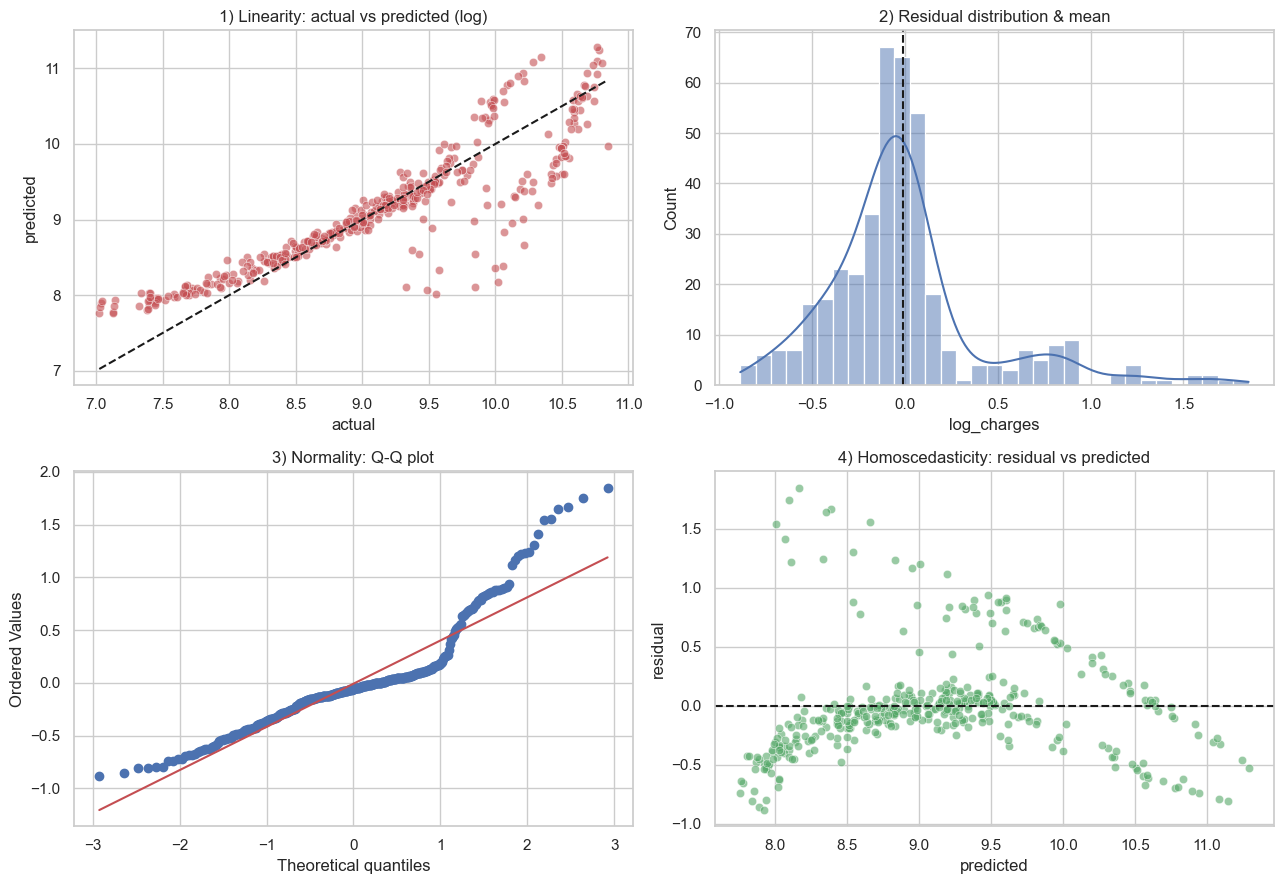

In [22]:
pred_lr = lin_reg.predict(X_test)
residual = y_test - pred_lr

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.scatterplot(x=y_test, y=pred_lr, ax=axes[0, 0], color='r', alpha=0.6)
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
axes[0, 0].set(title='1) Linearity: actual vs predicted (log)', xlabel='actual', ylabel='predicted')

sns.histplot(residual, kde=True, ax=axes[0, 1], color='b')
axes[0, 1].axvline(residual.mean(), c='k', ls='--')
axes[0, 1].set_title('2) Residual distribution & mean')

stats.probplot(residual, dist='norm', plot=axes[1, 0])
axes[1, 0].set_title('3) Normality: Q-Q plot')

sns.scatterplot(x=pred_lr, y=residual, ax=axes[1, 1], color='g', alpha=0.6)
axes[1, 1].axhline(0, c='k', ls='--')
axes[1, 1].set(title='4) Homoscedasticity: residual vs predicted', xlabel='predicted', ylabel='residual')
plt.tight_layout(); plt.show()

> **ผลการตรวจ:** กราฟ 1 มีจุดกลุ่มหนึ่งเบี่ยงจากเส้น, Residual เบ้ขวา, Q-Q ปลายบนโค้งออก
> → สมมติฐานไม่ผ่านทั้งหมด แปลว่าความสัมพันธ์จริง **ไม่เป็นเส้นตรงล้วน** (มี Interaction ระหว่าง smoker × bmi ตามที่เห็นในข้อ 5.4)
> → ควรทดลองโมเดลที่จับความสัมพันธ์ไม่เป็นเส้นตรงได้ ได้แก่ Tree

### 7.6 การวิเคราะห์ผล Linear Regression

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| คำนวณเองตรงกับ sklearn หรือไม่ | θ จาก Normal Equation = θ จาก sklearn ทุกตัว | `fit()` คือการแก้สมการ θ = (XᵀX)⁻¹Xᵀy |
| Overfit หรือไม่ | R² (log) Train 0.761 vs Test 0.787 | ไม่ Overfit (Test สูงกว่าเล็กน้อยเป็นเรื่องปกติจากการสุ่มแบ่ง) |
| ทำนายพลาดเฉลี่ยเท่าใด | MAE **$4,309** | ≈ 32% ของค่าประกันเฉลี่ย ($13,270) — ค่อนข้างมาก |
| มีการทำนายพลาดหนักหรือไม่ | RMSE **$8,213** (เกือบ 2 เท่าของ MAE) | มีบางคนที่ทำนายพลาดหนักมาก (กลุ่มค่าประกันสูง) |
| อธิบายความแปรปรวนได้เพียงใด? | R² (log) 0.787 แต่ **R² ($) 0.533** | วัดเป็นดอลลาร์จริง อธิบายได้เพียงครึ่งเดียว |
| ปัจจัยไหนมีผล? | สูบบุหรี่ +373%, อายุ +3.4%/ปี, BMI +1.2%/หน่วย | จุดเด่น: บอกขนาดผลของแต่ละปัจจัยเป็นตัวเลขได้ |
| สมมติฐานผ่านหรือไม่ | Residual เบ้ขวา, Q-Q โค้งปลายบน | ความสัมพันธ์ไม่เป็นเส้นตรงล้วน |

> **สรุป:** ตีความง่ายที่สุด (บอกได้ว่าแต่ละปัจจัยเพิ่มค่าประกันกี่ %) แต่ **แม่นน้อย** เพราะจับ Interaction
> "สูบบุหรี่ × BMI ≥ 30" ไม่ได้ ระวังด้วยว่า **R² ในสเกล log สูงกว่าความแม่นยำที่แท้จริง** ต้องวัดในสเกลดอลลาร์เสมอ

---
# ขั้นที่ 8: โมเดลที่ 2 — Decision Tree Regressor

### หลักการ
แบ่งข้อมูลด้วยคำถาม Yes/No ไปเรื่อยๆ (เช่น *สูบบุหรี่?* → *BMI > 30?*) แต่ละใบ (leaf) ทำนายด้วย **ค่าเฉลี่ย** ของข้อมูลในใบนั้น
เลือกจุดแบ่งที่ทำให้ **MSE ภายในกลุ่มลูกต่ำที่สุด** → จับ Interaction ได้เองโดยธรรมชาติ

### 8.1 เลือก `max_depth` ด้วย Cross-Validation

In [23]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV

kf = KFold(n_splits=5, shuffle=True, random_state=23)
rows = []
for d in [2, 3, 4, 5, 6, 8, None]:
    m = DecisionTreeRegressor(max_depth=d, random_state=23)
    cv = cross_val_score(m, X_train, y_train, cv=kf, scoring='r2').mean()
    m.fit(X_train, y_train)
    rows.append({'max_depth': str(d), 'R² train': m.score(X_train, y_train), 'CV R²': cv})
depth_df = pd.DataFrame(rows).round(3)
depth_df

,max_depth,R² train,CV R²
0,2,0.726,0.722
1,3,0.795,0.776
2,4,0.816,0.796
3,5,0.833,0.793
4,6,0.854,0.754
5,8,0.892,0.748
6,None,0.997,0.644


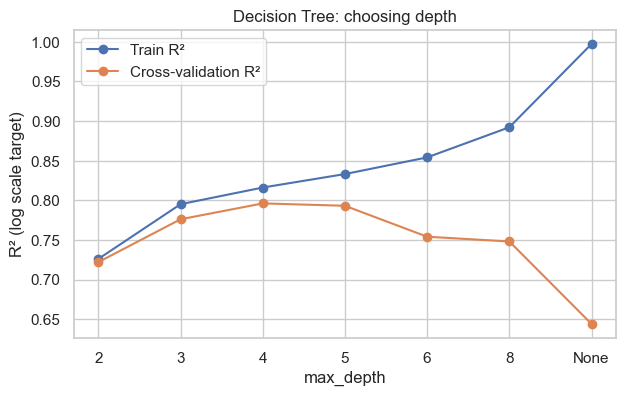

In [24]:
plt.figure(figsize=(7, 4))
plt.plot(depth_df['max_depth'], depth_df['R² train'], 'o-', label='Train R²')
plt.plot(depth_df['max_depth'], depth_df['CV R²'], 'o-', label='Cross-validation R²')
plt.xlabel('max_depth'); plt.ylabel('R² (log scale target)'); plt.title('Decision Tree: choosing depth')
plt.legend(); plt.show()

> **ข้อสังเกต:** CV R² สูงสุดที่ `max_depth = 4` หลังจากนั้น Train ยังเพิ่ม แต่ CV ลดลง (Overfitting) — ไม่จำกัดความลึก Train R² ≈ 1.0 แต่ CV ต่ำที่สุด

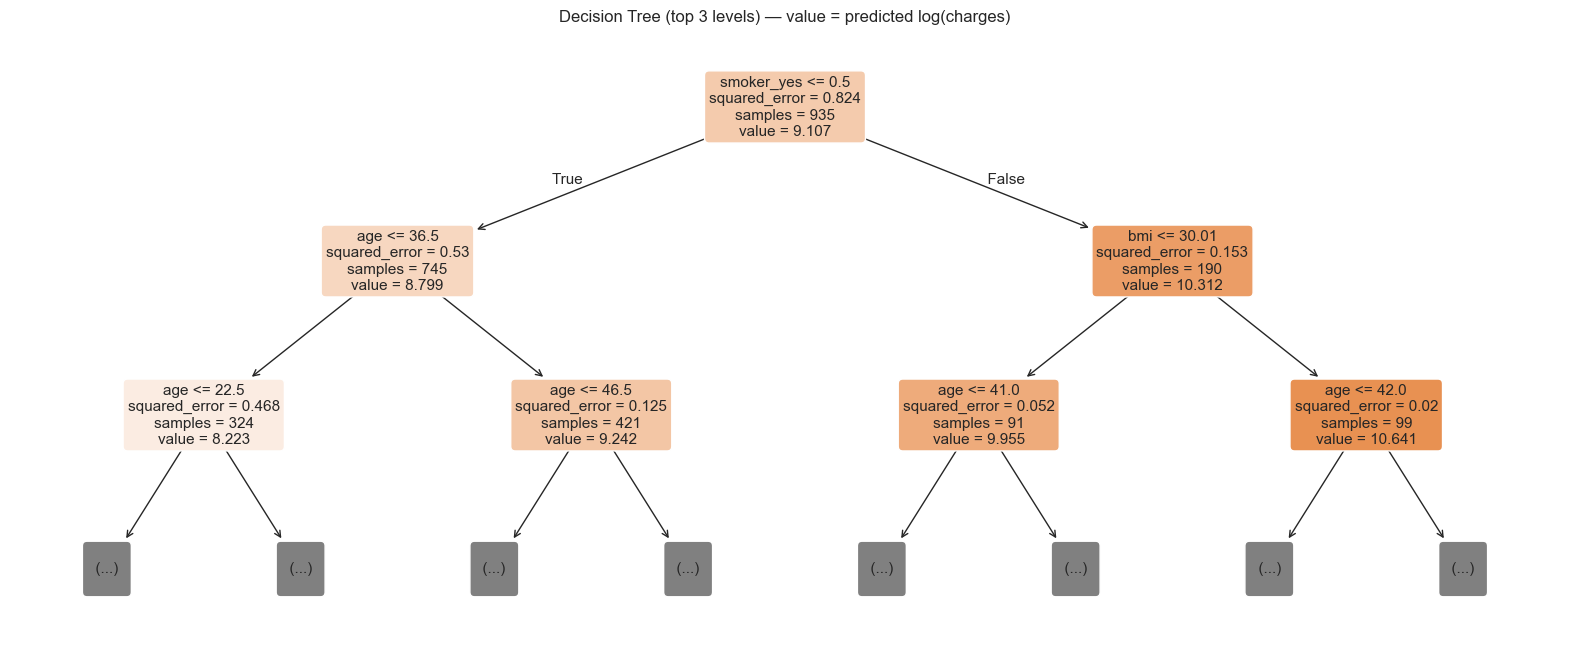

In [25]:
tree = DecisionTreeRegressor(max_depth=4, random_state=23).fit(X_train, y_train)
results.append(evaluate(tree, 'Decision Tree (depth=4)'))

plt.figure(figsize=(20, 8))
plot_tree(tree, max_depth=2, feature_names=X.columns, filled=True, rounded=True, fontsize=11)
plt.title('Decision Tree (top 3 levels) — value = predicted log(charges)')
plt.show()

> **ข้อสังเกต:** ต้นไม้เลือกแบ่งด้วย `smoker_yes` ก่อน แล้วใช้ `bmi` / `age` ต่อ — ตรงกับ Insight จาก EDA ทุกประการ

### 8.2 ผลบน Test Set

In [26]:
pd.DataFrame(results).set_index('Model').round(3)     # เทียบกับ Linear Regression

,R² train (log),R² test (log),MAE ($),RMSE ($),R² test ($)
Model,,,,,
Linear Regression,0.761,0.787,4308.768,8212.904,0.533
Decision Tree (depth=4),0.816,0.828,2448.679,4808.043,0.840


### 8.3 การวิเคราะห์ผล Decision Tree

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| ไม่จำกัดความลึกเป็นอย่างไร? | Train R² **0.997** vs CV R² **0.644** | Overfit หนัก — ต่ำกว่า Linear Regression |
| ความลึกที่เลือก | `max_depth = 4` (CV R² สูงสุด 0.796) | เลือกจาก CV ไม่ใช่จาก Test |
| Overfit หรือไม่ (หลังจูน)? | R² (log) Train 0.816 vs Test 0.828 | ไม่ Overfit |
| ทำนายพลาดเฉลี่ยเท่าใด | MAE **$2,449** | ลดลง **43%** จาก Linear Regression ($4,309) |
| มีการทำนายพลาดหนักหรือไม่ | RMSE **$4,808** | ลดลงเกือบครึ่ง — ทำนายกลุ่มค่าประกันสูงได้ดีขึ้นมาก |
| อธิบายความแปรปรวนได้เพียงใด? | R² ($) **0.840** | เพิ่มจาก 0.533 |
| ต้นไม้ตัดสินอย่างไร? | แบ่งด้วย `smoker_yes` ก่อน แล้วจึง `bmi` / `age` | เรียนรู้ Interaction ที่ Linear Regression ทำไม่ได้ |

> **สรุป:** ต้นไม้เพียง 4 ชั้นแม่นกว่า Linear Regression มาก เพราะจับ "การสูบบุหรี่ × ภาวะอ้วน" ได้เอง และยังอ่านเป็นกฎได้
> แต่ต้อง **จำกัดความลึก** เสมอ มิฉะนั้นจะเกิด Overfitting อย่างรุนแรง

---
# ขั้นที่ 9: โมเดลที่ 3 — Random Forest Regressor

### หลักการ
สร้าง Decision Tree หลายร้อยต้นจากข้อมูลที่สุ่มต่างกัน แล้ว **เฉลี่ยคำทำนาย** → แม่นและเสถียรกว่าต้นเดียว

### 9.1 จูน Hyperparameter ด้วย GridSearchCV

In [27]:
from sklearn.ensemble import RandomForestRegressor

grid_rf = GridSearchCV(RandomForestRegressor(n_estimators=300, random_state=23),
                       param_grid={'max_depth': [3, 4, 5, 6, 8, None], 'min_samples_leaf': [1, 5]},
                       cv=kf, scoring='r2', n_jobs=-1)
grid_rf.fit(X_train, y_train)
rf = grid_rf.best_estimator_

print("ค่าที่ดีที่สุด:", grid_rf.best_params_)
print(f"CV R² ที่ดีที่สุด: {grid_rf.best_score_:.3f}")
results.append(evaluate(rf, 'Random Forest'))

ค่าที่ดีที่สุด: {'max_depth': 5, 'min_samples_leaf': 1}
CV R² ที่ดีที่สุด: 0.806


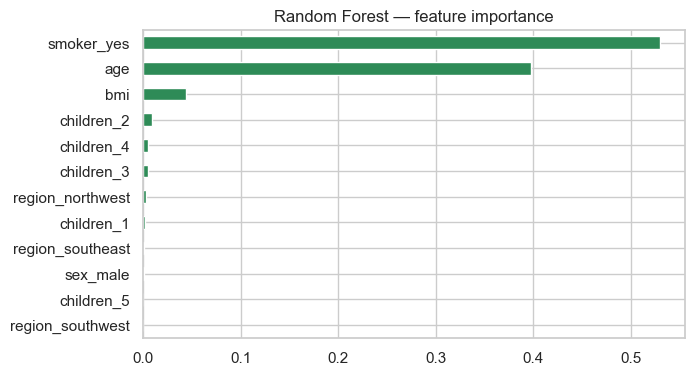

In [28]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh', figsize=(7, 4), color='seagreen', title='Random Forest — feature importance')
plt.show()

> **ข้อสังเกต:** `smoker_yes` สำคัญที่สุด รองลงมาอย่างใกล้เคียงคือ `age` และ `bmi` ตามลำดับ — เพศ ภูมิภาค จำนวนบุตร แทบไม่มีผล

### 9.2 ผลบน Test Set

In [29]:
pd.DataFrame(results).set_index('Model').round(3)     # เทียบกับสองโมเดลก่อนหน้า

,R² train (log),R² test (log),MAE ($),RMSE ($),R² test ($)
Model,,,,,
Linear Regression,0.761,0.787,4308.768,8212.904,0.533
Decision Tree (depth=4),0.816,0.828,2448.679,4808.043,0.840
Random Forest,0.843,0.838,2253.798,4656.914,0.850


### 9.3 การวิเคราะห์ผล Random Forest

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| Hyperparameter ที่ดีที่สุด | `max_depth=5`, `min_samples_leaf=1` (CV R² 0.806) | ต้นไม้ไม่ต้องลึกมาก |
| Overfit หรือไม่ | R² (log) Train 0.843 vs Test 0.838 | ไม่ Overfit |
| ทำนายพลาดเฉลี่ยเท่าใด | MAE **$2,254** | ต่ำสุด — ดีกว่า Decision Tree ~8% (≈ 17% ของค่าเฉลี่ย) |
| มีการทำนายพลาดหนักหรือไม่ | RMSE **$4,657** | ต่ำสุด |
| อธิบายความแปรปรวนได้เพียงใด? | R² ($) **0.850** | สูงสุด |
| ปัจจัยสำคัญ | สูบบุหรี่ 0.53 > อายุ 0.40 > BMI 0.04 | เพศ ภูมิภาค จำนวนบุตร แทบไม่มีผล |

> **สรุป:** แม่นที่สุดในสามโมเดล แต่ดีกว่า Decision Tree **เพียงเล็กน้อย** (R² 0.850 vs 0.840)
> แลกกับการที่อ่านเป็นกฎไม่ได้ (เป็นค่าเฉลี่ยของต้นไม้ 300 ต้น)

---
# ขั้นที่ 10: เปรียบเทียบ 3 โมเดลและเลือกโมเดลที่ดีที่สุด

### 10.1 ตารางเปรียบเทียบ (Test Set)

In [30]:
results_df = pd.DataFrame(results).set_index('Model').round(3)
results_df.style.format('{:.3f}', subset=['R² train (log)', 'R² test (log)', 'R² test ($)']) \
          .format('{:,.0f}', subset=['MAE ($)', 'RMSE ($)']) \
          .highlight_max(axis=0, color='#c7e9c0', subset=['R² test (log)', 'R² test ($)']) \
          .highlight_min(axis=0, color='#c7e9c0', subset=['MAE ($)', 'RMSE ($)'])

,R² train (log),R² test (log),MAE ($),RMSE ($),R² test ($)
Model,,,,,
Linear Regression,0.761,0.787,"4,309","8,213",0.533
Decision Tree (depth=4),0.816,0.828,"2,449","4,808",0.840
Random Forest,0.843,0.838,"2,254","4,657",0.850


### 10.2 กราฟ Actual vs Predicted (สเกลดอลลาร์)

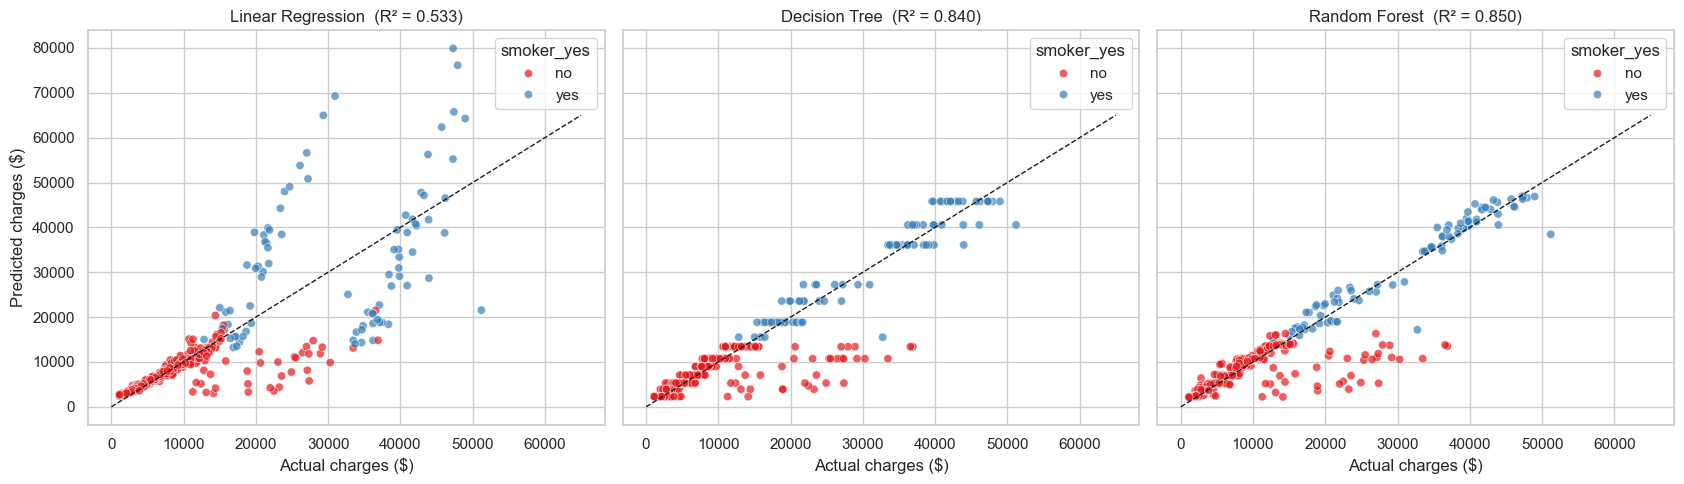

In [31]:
models = {'Linear Regression': lin_reg, 'Decision Tree': tree, 'Random Forest': rf}
actual = np.exp(y_test)

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    pred = np.exp(m.predict(X_test))
    smoker = X_test['smoker_yes'].map({0: 'no', 1: 'yes'})
    sns.scatterplot(x=actual, y=pred, hue=smoker, palette='Set1', alpha=0.7, ax=ax)
    ax.plot([0, 65000], [0, 65000], 'k--', lw=1)
    ax.set(title=f'{name}  (R² = {r2_score(actual, pred):.3f})', xlabel='Actual charges ($)', ylabel='Predicted charges ($)')
plt.tight_layout(); plt.show()

> **ข้อสังเกต:** Linear Regression ทำนายกลุ่มผู้สูบที่ค่าประกันสูง (มุมขวาบน) **ต่ำกว่าจริง** มาก ส่วนโมเดล Tree ทั้งสองจุดเกาะเส้นทแยงดีกว่าชัดเจน

### 10.3 ใช้โมเดลทำนายลูกค้าใหม่
ข้อมูลใหม่ต้องผ่าน **ขั้นตอนเตรียมข้อมูลเดียวกัน** (One-Hot แล้วจัดคอลัมน์ให้ตรงกับตอนเทรน)

In [32]:
new_people = pd.DataFrame({
    'age':      [40, 40, 40],
    'sex':      ['male', 'male', 'male'],
    'bmi':      [25.0, 34.0, 34.0],
    'children': [1, 1, 1],
    'smoker':   ['no', 'no', 'yes'],
    'region':   ['southeast'] * 3,
}, index=['ไม่สูบ BMI 25', 'ไม่สูบ BMI 34', 'สูบ BMI 34'])

new_X = pd.get_dummies(new_people, columns=categorical_columns, prefix=categorical_columns, dtype=int)
new_X = new_X.reindex(columns=X.columns, fill_value=0)

pd.DataFrame({name: np.exp(m.predict(new_X)).round(0) for name, m in models.items()}, index=new_people.index)

,Linear Regression,Decision Tree,Random Forest
ไม่สูบ BMI 25,5913.0,7073.0,6887.0
ไม่สูบ BMI 34,6569.0,7073.0,6918.0
สูบ BMI 34,31091.0,36076.0,39921.0


> **ข้อสังเกต:** ผู้ชายอายุ 40 ไม่สูบ: BMI 25 หรือ 34 ค่าประกันแทบไม่ต่างกัน (~$5,900–7,100)
> แต่ถ้า **สูบ + BMI 34** Linear Regression ทำนาย $31,091 ขณะที่ Tree ทำนาย $36,076–39,921 → Linear Regression ทำนายกลุ่มนี้ **ต่ำเกินจริง**

### 10.4 สรุปผลการเปรียบเทียบ

| โมเดล | MAE ($) | RMSE ($) | R² ($) | Overfit? | จุดเด่น |
|---|---|---|---|---|---|
| Linear Regression | 4,309 | 8,213 | 0.533 | ไม่ | ตีความง่ายที่สุด บอกผลเป็น % ได้ |
| Decision Tree (depth 4) | 2,449 | 4,808 | 0.840 | ไม่ | แม่นใกล้ RF และอ่านเป็นกฎได้ |
| Random Forest | **2,254** | **4,657** | **0.850** | ไม่ | แม่นที่สุด |

**ข้อค้นพบหลัก**
1. **โมเดล Tree ดีกว่า Linear Regression มาก** (R² 0.84–0.85 vs 0.53) เพราะข้อมูลมี Interaction "สูบบุหรี่ × BMI ≥ 30" ที่เส้นตรงจับไม่ได้
2. **Random Forest ดีกว่า Decision Tree เพียงเล็กน้อย** (MAE ต่างกันเพียง ~$200)
3. **RMSE ≈ 2 เท่าของ MAE ทุกโมเดล** → ยังมีบางคนที่ทำนายพลาดหนัก (ค่าประกันสูงมาก)
4. **ปัจจัยสำคัญ:** การสูบบุหรี่ > อายุ > BMI (BMI มีผลเฉพาะเมื่อสูบด้วย) ส่วนเพศ ภูมิภาค จำนวนบุตร แทบไม่มีผล
5. **R² ในสเกล log อาจทำให้เข้าใจผิดได้** — Linear Regression ได้ 0.787 (log) แต่ในสเกลดอลลาร์จริงเพียง 0.533

**คำแนะนำ**
- ต้องการความแม่นสูงสุด → **Random Forest**
- ต้องการอธิบายให้ลูกค้า/ผู้บริหารเข้าใจ → **Decision Tree (depth 4)** โดยเสียความแม่นยำเพียงเล็กน้อย
- หมายเหตุ: ดูแบบฝึกหัดข้อ 1: Linear Regression ที่ **ไม่ใส่ log + เพิ่ม Feature `smoker_obese`** ได้ R² ($) **0.858** ชนะทุกโมเดล!

> **ตัวอย่างการเขียนสรุปผลในข้อสอบ:**
> *"เลือก Random Forest เพราะได้ MAE ต่ำสุด ($2,254) และ R² สูงสุด (0.850) บน Test Set โดยไม่ Overfit (R² Train 0.843 vs Test 0.838)
> ดีกว่า Linear Regression (R² 0.533) อย่างชัดเจน เพราะจับความสัมพันธ์ระหว่างการสูบบุหรี่กับ BMI ได้
> ข้อจำกัดคือ RMSE ยังสูงเกือบ 2 เท่าของ MAE แสดงว่ายังทำนายพลาดหนักในบางราย"*

---
## รายการตรวจสอบสำหรับการสอบ (Checklist): Regression
- [ ] ตรวจค่าหาย, ข้อมูลซ้ำ, Outlier (และอธิบายว่าทำไมเก็บ/ลบ)
- [ ] ดูการกระจายของ Target — ถ้าเบ้มาก ทดลอง log
- [ ] EDA หาความสัมพันธ์ของแต่ละ Feature กับ Target
- [ ] One-Hot (`drop_first=True` สำหรับ Linear Regression)
- [ ] Split → เทรน 2–3 โมเดล → เลือก Hyperparameter ด้วย CV
- [ ] รายงาน MAE, RMSE, R² (ถ้าแปลง Target ต้องแปลงกลับก่อนรายงาน)
- [ ] Linear Regression: ตรวจ Residual plots
- [ ] สรุปเลือกโมเดลพร้อมเหตุผล

## แบบฝึกหัด
1. ทดลอง Linear Regression 4 แบบ แล้วเทียบ R² (ดอลลาร์):
   (ก) Target แบบ log (แบบในบทนี้) (ข) Target เป็นหน่วยดอลลาร์โดยไม่แปลง log
   (ค)–(ง) แบบ ก และ ข แต่เพิ่ม Feature ใหม่ `smoker_obese = smoker_yes × (bmi ≥ 30)` จาก Insight ในข้อ 5.4
2. เพิ่มโมเดลที่ 4: `KNeighborsRegressor` (ต้อง Scale ข้อมูลก่อน) แล้วเพิ่มลงในตารางเปรียบเทียบ

In [33]:
# เฉลยข้อ 1
add_fe = lambda d: d.assign(smoker_obese=d['smoker_yes'] * (d['bmi'] >= 30).astype(int))
y_train_usd, y_test_usd = np.exp(y_train), np.exp(y_test)

rows = []
for fe_name, Xtr, Xte in [('ไม่มี', X_train, X_test), ('+ smoker_obese', add_fe(X_train), add_fe(X_test))]:
    m_log = LinearRegression().fit(Xtr, y_train)          # เรียน log(charges)
    m_usd = LinearRegression().fit(Xtr, y_train_usd)      # เรียน charges ตรงๆ
    rows.append({'Feature เพิ่ม': fe_name,
                 'R² ($) Target = log': r2_score(y_test_usd, np.exp(m_log.predict(Xte))),
                 'R² ($) Target = ดอลลาร์': r2_score(y_test_usd, m_usd.predict(Xte))})
pd.DataFrame(rows).round(3)

,Feature เพิ่ม,R² ($) Target = log,R² ($) Target = ดอลลาร์
0,ไม่มี,0.533,0.743
1,+ smoker_obese,0.541,0.858


> **บทเรียนสำคัญจากแบบฝึกหัดนี้**
> 1. **log ไม่ได้ดีเสมอไป** — ต้นฉบับเลือก log เพราะ Target เบ้ แต่เมื่อวัดในสเกลดอลลาร์ การไม่ใส่ log กลับได้ผลดีกว่า → **ต้องทดลองและวัดผลในสเกลจริงเสมอ**
> 2. **Feature Engineering จาก EDA ทรงพลังมาก** — เพิ่มเพียง 1 คอลัมน์ Linear Regression ก็แม่นใกล้เคียงหรือดีกว่า Random Forest และยังตีความง่ายกว่า